# Vanishing Gradient Problem

A problem in deep neural networks where the gradient will be vanishingly small making the model training ineffective.

In [48]:
# importing libraries 
import matplotlib.pyplot as plt 
import numpy as np 
import tensorflow as tf 
import keras 
from sklearn.datasets import make_moons 
from sklearn.model_selection import train_test_split 
from keras.layers import Dense 
from keras.models import Sequential

In [49]:
# generating the dataset 
X,Y = make_moons(n_samples=500,noise=0.08,random_state=42)

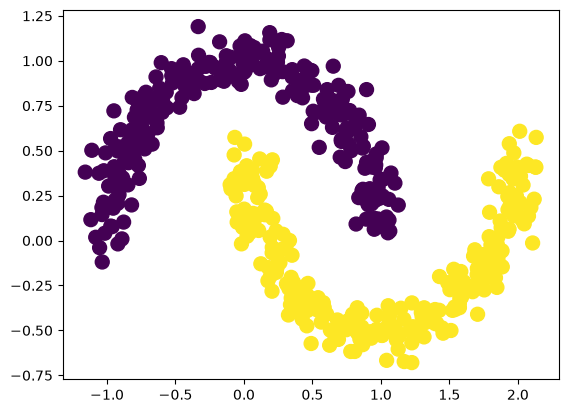

In [50]:
plt.scatter(X[:,0],X[:,1],c=Y,s=100)

In [51]:
# splitting the data into training and testing parts 
X_train,X_test,Y_train,Y_test = train_test_split(X,Y,test_size=0.2,random_state=42)

In [52]:
# defining a deep neural network 

model = Sequential() 

model.add(Dense(10,activation='sigmoid'))
model.add(Dense(10,activation='sigmoid'))
model.add(Dense(10,activation='sigmoid'))
model.add(Dense(10,activation='sigmoid'))
model.add(Dense(10,activation='sigmoid'))
model.add(Dense(10,activation='sigmoid'))
model.add(Dense(10,activation='sigmoid'))
model.add(Dense(10,activation='sigmoid'))
model.add(Dense(10,activation='sigmoid'))
model.add(Dense(10,activation='sigmoid'))
model.add(Dense(10,activation='sigmoid'))
model.add(Dense(10,activation='sigmoid'))
model.add(Dense(1,activation='sigmoid'))

In [53]:
model.compile(loss='binary_crossentropy',optimizer='adam',metrics=['accuracy'])

In [54]:
model.fit(X_train,Y_train,epochs=1)

13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.5175 - loss: 0.7078


In [55]:
model.get_weights()[0]

array([[-0.39752656, -0.16155173, -0.20144999,  0.42015645,  0.08356333,
        -0.38737276,  0.01847793, -0.6464505 ,  0.6815534 ,  0.23969878],
       [ 0.6407694 ,  0.3401644 ,  0.2545267 ,  0.49181786, -0.32355046,
        -0.04198653,  0.20834385,  0.58248556,  0.6216613 ,  0.66328686]],
      dtype=float32)

In [56]:
old_weights = model.get_weights()[0]

In [57]:
model.fit(X_train,Y_train,epochs=1)

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5175 - loss: 0.7007 


In [58]:
new_weights = model.get_weights()[0]

In [59]:
# fetching the learning rate of the model 
model.optimizer.get_config()['learning_rate']

0.0010000000474974513

In [60]:
lr = model.optimizer.get_config()['learning_rate'] 
gradient = (old_weights-new_weights)/lr 
percent_change = abs(100*(old_weights-new_weights)/old_weights)

In [61]:
gradient

array([[-0.0244379 ,  0.00105798,  0.00572205,  0.00965595,  0.03471971,
        -0.02124905,  0.02256594, -0.00607967, -0.01597404, -0.01849234],
       [ 0.01549721, -0.00101328, -0.00336766, -0.0064075 , -0.02044439,
         0.01413003, -0.01402199,  0.00411272,  0.01120567,  0.01108646]],
      dtype=float32)

In [62]:
percent_change

array([[0.00614749, 0.00065489, 0.00284043, 0.00229818, 0.04154897,
        0.00548543, 0.1221238 , 0.00094047, 0.00234377, 0.00771482],
       [0.00241853, 0.00029788, 0.00132311, 0.00130282, 0.00631876,
        0.03365372, 0.00673022, 0.00070606, 0.00180254, 0.00167144]],
      dtype=float32)

## Reducing the model's complexity (i.e. downgrading a deep neural network into a shallow neural network can solve the problem of vanishing gradient)

In [94]:
shallow_model = Sequential() 

shallow_model.add(Dense(10,activation='sigmoid',input_dim=2))
shallow_model.add(Dense(10,activation='sigmoid'))
shallow_model.add(Dense(10,activation='sigmoid'))
shallow_model.add(Dense(1,activation='sigmoid'))

In [95]:
shallow_model.compile(loss='binary_crossentropy',optimizer='adam',metrics=['accuracy'])

In [96]:
shallow_model.fit(X_train,Y_train,epochs=1)

13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.5175 - loss: 0.7065


In [97]:
shallow_model.get_weights()[0]

array([[-0.2876566 ,  0.4339623 , -0.6928885 , -0.49056023, -0.5550474 ,
         0.51480824, -0.24694207,  0.5446815 , -0.47414735, -0.11336998],
       [ 0.5971771 ,  0.5654092 , -0.32124415, -0.7113107 ,  0.14034443,
        -0.21240158, -0.13623796,  0.67662704, -0.02410332,  0.01105319]],
      dtype=float32)

In [98]:
old_weights = shallow_model.get_weights()[0]

In [99]:
shallow_model.fit(X_train,Y_train,epochs=1)

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5175 - loss: 0.7004 


In [100]:
shallow_model.get_weights()[0]

array([[-0.27553034,  0.44654098, -0.705034  , -0.47826016, -0.55897236,
         0.5267397 , -0.2545948 ,  0.5323055 , -0.48639286, -0.12357806],
       [ 0.58456904,  0.5523905 , -0.30862054, -0.7240097 ,  0.14561461,
        -0.22487631, -0.12848972,  0.68940705, -0.01146846,  0.02172223]],
      dtype=float32)

In [101]:
new_weights = shallow_model.get_weights()[0]

In [102]:
# fetching the learning rate of the shallow model 
shallow_model.optimizer.get_config()['learning_rate']

0.0010000000474974513

In [103]:
lr = shallow_model.optimizer.get_config()['learning_rate']
gradient = (old_weights-new_weights)/lr 
percent_change = abs(100*(old_weights-new_weights)/old_weights)

In [104]:
gradient

array([[-12.1262665, -12.578695 ,  12.145518 , -12.300074 ,   3.9249656,
        -11.9314785,   7.6527295,  12.37601  ,  12.245505 ,  10.208077 ],
       [ 12.60805  ,  13.018667 , -12.623608 ,  12.699007 ,  -5.2701826,
         12.4747305,  -7.7482457, -12.78001  , -12.634859 , -10.669041 ]],
      dtype=float32)

In [105]:
percent_change

array([[ 4.2155356,  2.8985689,  1.7528822,  2.5073524,  0.7071407,
         2.317655 ,  3.0989978,  2.2721555,  2.5826373,  9.004215 ],
       [ 2.1112752,  2.3025215,  3.9295993,  1.7852969,  3.755178 ,
         5.8731813,  5.6872888,  1.8887821, 52.419586 , 96.52452  ]],
      dtype=float32)